# Day 7: CSV Analysis, Visualization and TensorFlow Intro
**System 7 Internship – Week 1 (Python & Data Science Foundations)**

**Task 1:** Analyze a CSV dataset and produce charts and summary statistics (Pandas, Matplotlib, Seaborn).

**Dataset:** `tested.csv` – Titanic passenger records (418 passengers) with columns such as `Survived`, `Pclass`, `Sex`, `Age`, `Fare` and `Embarked`.

**Steps:** 1. Load the data → 2. Explore → 3. Clean missing values → 4. Summary statistics → 5. Charts → 6. Conclusions → 7. TensorFlow intro

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Load the dataset
In Google Colab, upload `tested.csv` first (folder icon on the left → upload), or run the cell below the loader.

In [2]:
# If running in Colab and the file is not uploaded yet, this opens an upload button
import os
if not os.path.exists("tested.csv"):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError("Put tested.csv in the same folder as this notebook")

df = pd.read_csv("tested.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


## 3. Explore the data

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (418, 12)

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    str    
 4   Sex          418 non-null    str    
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    str    
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     str    
 11  Embarked     418 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 39.3 KB


In [4]:
# Column names and data types
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [5]:
# Missing values per column, with percentage
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct})[missing > 0]

,missing,percent
Age,86,20.6
Fare,1,0.2
Cabin,327,78.2


In [6]:
# Duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


## 4. Clean the data
- **Age** (about 20% missing): fill with the median age of the passenger's class (`Pclass`) and sex.
- **Fare** (1 missing): fill with the median fare of that passenger's class.
- **Cabin** (about 78% missing): too many gaps to fill, so create a simpler `HasCabin` column (True/False) and drop `Cabin`.

I keep a copy of the original `Age` to compare before and after.

In [7]:
df_clean = df.copy()
age_before = df["Age"].copy()

df_clean["Age"] = df_clean["Age"].fillna(
    df_clean.groupby(["Pclass", "Sex"])["Age"].transform("median")
)
df_clean["Fare"] = df_clean["Fare"].fillna(
    df_clean.groupby("Pclass")["Fare"].transform("median")
)
df_clean["HasCabin"] = df_clean["Cabin"].notnull()
df_clean = df_clean.drop(columns=["Cabin"])

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
HasCabin       0
dtype: int64


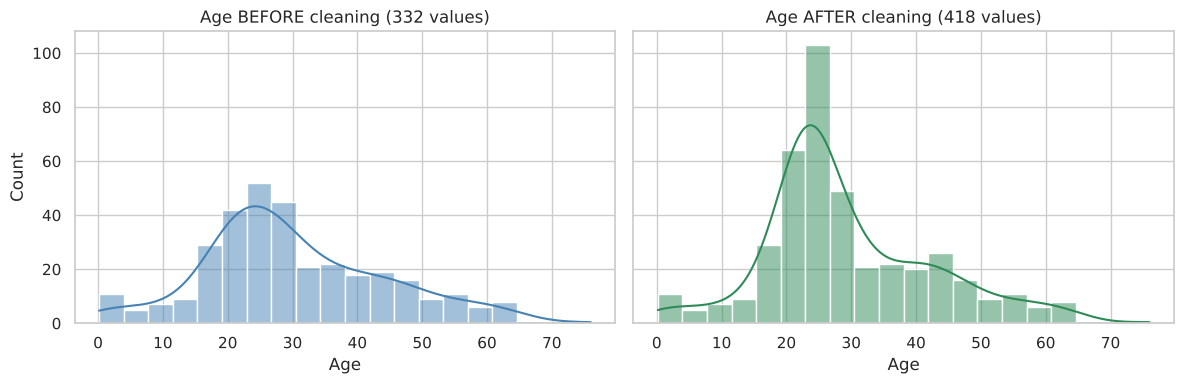

In [8]:
# Before vs after: Age distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
sns.histplot(age_before.dropna(), bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"Age BEFORE cleaning ({age_before.notnull().sum()} values)")
sns.histplot(df_clean["Age"], bins=20, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"Age AFTER cleaning ({df_clean['Age'].notnull().sum()} values)")
for ax in axes:
    ax.set_xlabel("Age")
plt.tight_layout()
plt.show()

## 5. Summary statistics

In [9]:
# Numeric columns
df_clean[["Age", "SibSp", "Parch", "Fare"]].describe().round(2)

,Age,SibSp,Parch,Fare
count,418.00,418.00,418.00,418.00
mean,29.30,0.45,0.39,35.56
std,13.04,0.90,0.98,55.86
min,0.17,0.00,0.00,0.00
25%,22.00,0.00,0.00,7.90
50%,25.00,0.00,0.00,14.45
75%,36.38,1.00,0.00,31.47
max,76.00,8.00,9.00,512.33


In [10]:
# Extra statistics
print("Mean age:     ", round(df_clean["Age"].mean(), 2))
print("Median age:   ", df_clean["Age"].median())
print("Mean fare:    ", round(df_clean["Fare"].mean(), 2))
print("Median fare:  ", df_clean["Fare"].median())
print("Highest fare: ", df_clean["Fare"].max())
print("Age std dev:  ", round(df_clean["Age"].std(), 2))

Mean age:      29.3
Median age:    25.0
Mean fare:     35.56
Median fare:   14.4542
Highest fare:  512.3292
Age std dev:   13.04


In [11]:
# Categorical columns: how many of each
for col in ["Survived", "Pclass", "Sex", "Embarked"]:
    print(f"--- {col} ---")
    print(df_clean[col].value_counts())
    print()

--- Survived ---
Survived
0    266
1    152
Name: count, dtype: int64

--- Pclass ---
Pclass
3    218
1    107
2     93
Name: count, dtype: int64

--- Sex ---
Sex
male      266
female    152
Name: count, dtype: int64

--- Embarked ---
Embarked
S    270
C    102
Q     46
Name: count, dtype: int64



In [12]:
# Survival rate by group (mean of Survived = fraction who survived)
for col in ["Sex", "Pclass", "Embarked", "HasCabin"]:
    rate = (df_clean.groupby(col)["Survived"].mean() * 100).round(1)
    print(f"Survival rate by {col} (%):")
    print(rate.to_string())
    print()

Survival rate by Sex (%):
Sex
female    100.0
male        0.0

Survival rate by Pclass (%):
Pclass
1    46.7
2    32.3
3    33.0

Survival rate by Embarked (%):
Embarked
C    39.2
Q    52.2
S    32.6

Survival rate by HasCabin (%):
HasCabin
False    33.0
True     48.4



## 6. Charts

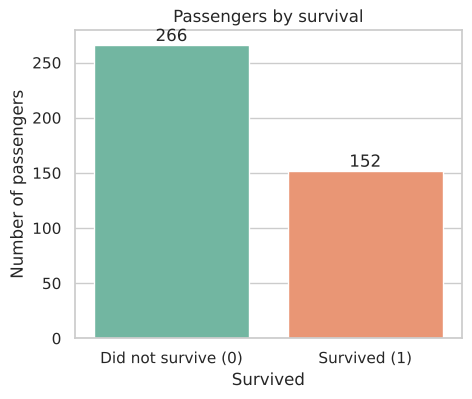

In [13]:
# Chart 1: Survived vs not survived
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_clean, x="Survived", hue="Survived", palette="Set2", legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Did not survive (0)", "Survived (1)"])
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title("Passengers by survival")
plt.ylabel("Number of passengers")
plt.show()

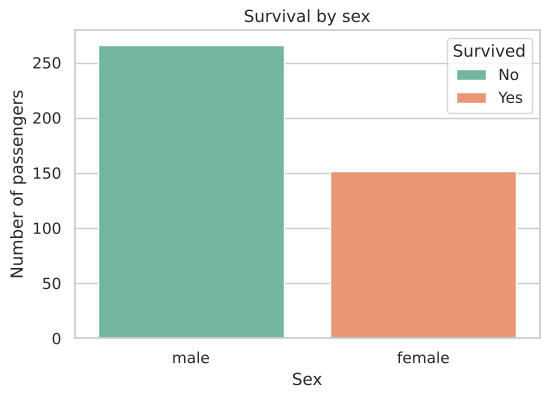

In [14]:
# Chart 2: Survival by sex
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_clean, x="Sex", hue="Survived", palette="Set2")
plt.title("Survival by sex")
plt.ylabel("Number of passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()

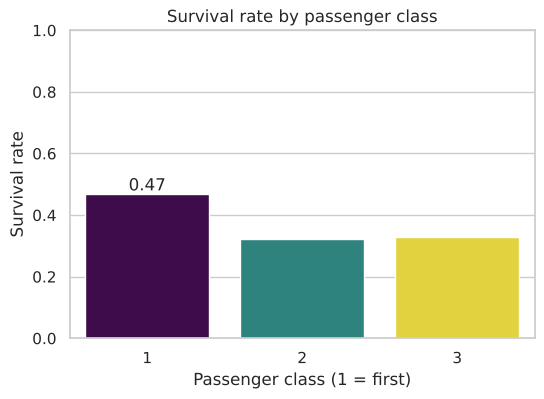

In [15]:
# Chart 3: Survival rate by passenger class
plt.figure(figsize=(6, 4))
ax = sns.barplot(data=df_clean, x="Pclass", y="Survived", hue="Pclass", palette="viridis", legend=False, errorbar=None)
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.title("Survival rate by passenger class")
plt.ylabel("Survival rate")
plt.xlabel("Passenger class (1 = first)")
plt.ylim(0, 1)
plt.show()

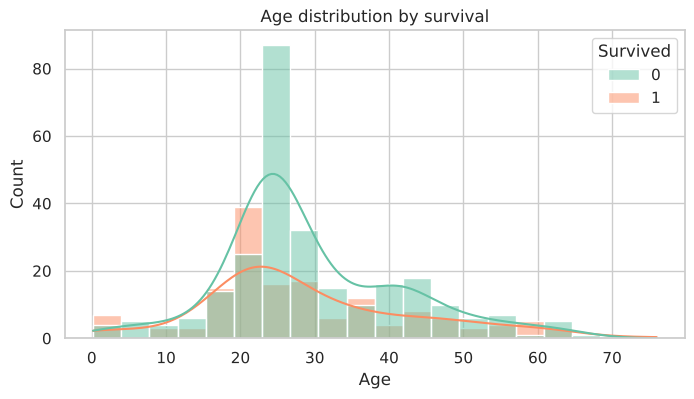

In [16]:
# Chart 4: Age distribution by survival
plt.figure(figsize=(8, 4))
sns.histplot(data=df_clean, x="Age", hue="Survived", bins=20, kde=True, palette="Set2", multiple="layer")
plt.title("Age distribution by survival")
plt.show()

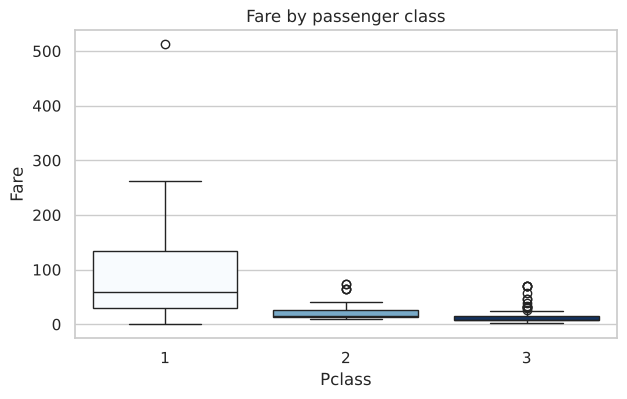

In [17]:
# Chart 5: Fare by class (box plot)
plt.figure(figsize=(7, 4))
sns.boxplot(data=df_clean, x="Pclass", y="Fare", hue="Pclass", palette="Blues", legend=False)
plt.title("Fare by passenger class")
plt.show()

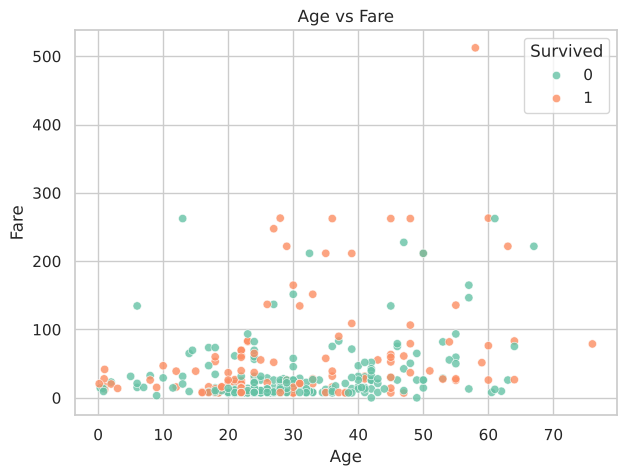

In [18]:
# Chart 6: Age vs Fare scatter plot
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="Age", y="Fare", hue="Survived", palette="Set2", alpha=0.8)
plt.title("Age vs Fare")
plt.show()

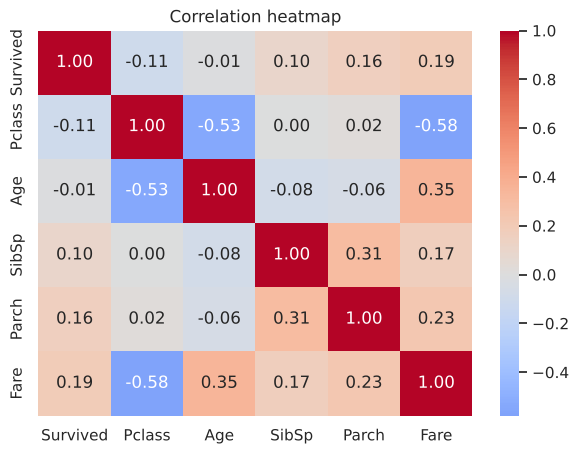

In [19]:
# Chart 7: Correlation heatmap of numeric columns
plt.figure(figsize=(7, 5))
corr = df_clean[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

## 7. Conclusions
- **Dataset size:** 418 passengers, 12 columns, no duplicate rows. **152 (36.4%) survived** and 266 did not.
- **Missing data:** `Age` was missing for 86 passengers (20.6%), `Fare` for 1, and `Cabin` for 327 (78.2%). Age and Fare were filled with group medians, and `Cabin` was turned into a `HasCabin` column.
- **Age:** the average passenger was about 29 years old (median 25). Ages range from a few months to 76.
- **Fare:** the average fare was about 35.56, but the median was only 14.45, so a few very expensive tickets (maximum 512.33) pull the average up. First class fares are much higher than second and third class.
- **Passenger class:** class 3 was the largest group (218 passengers). First class had the highest survival rate (46.7%), compared with 32.3% in class 2 and 33.0% in class 3.
- **Cabin:** passengers with a recorded cabin survived more often (48.4%) than those without (33.0%).
- **Embarked:** most passengers boarded at Southampton (S, 270).
- **Sex and survival:** in this file **every woman survived and every man died** (female 100%, male 0%). This is unusually perfect. It suggests this is a prepared test set where the `Survived` labels were generated from the `Sex` column, so this pattern should not be treated as a real-world finding. Real Titanic data also shows women survived at a much higher rate, but not 100%.
- **Correlations:** the heatmap shows that `Fare` and `Pclass` are negatively correlated (higher class number means a cheaper ticket), and `SibSp` and `Parch` are positively correlated (families travel together).


## 8. TensorFlow introduction
TensorFlow is a library for machine learning. Its basic data type is the **tensor**, a multi-dimensional array (similar to a NumPy array).

**Installation:** in Google Colab TensorFlow is already installed. On your own computer run `pip install tensorflow`.

In [20]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)

I0000 00:00:1792257954.440175     318 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792257954.502369     318 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792257955.902254     318 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


In [21]:
# Tensors of different dimensions
scalar = tf.constant(7)                              # 0-D
vector = tf.constant([1.0, 2.0, 3.0])                # 1-D
matrix = tf.constant([[1, 2], [3, 4]])               # 2-D
tensor3d = tf.constant([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])  # 3-D

for name, t in [("scalar", scalar), ("vector", vector), ("matrix", matrix), ("3-D tensor", tensor3d)]:
    print(f"{name}: shape={t.shape}, dtype={t.dtype}, dims={t.ndim}")

scalar: shape=(), dtype=<dtype: 'int32'>, dims=0
vector: shape=(3,), dtype=<dtype: 'float32'>, dims=1
matrix: shape=(2, 2), dtype=<dtype: 'int32'>, dims=2
3-D tensor: shape=(2, 2, 2), dtype=<dtype: 'int32'>, dims=3


In [22]:
# Basic tensor operations
a = tf.constant([[1, 2], [3, 4]])
b = tf.constant([[5, 6], [7, 8]])

print("a + b =\n", (a + b).numpy())
print("a * b (element-wise) =\n", (a * b).numpy())
print("a @ b (matrix multiply) =\n", tf.matmul(a, b).numpy())

a + b =
 [[ 6  8]
 [10 12]]
a * b (element-wise) =
 [[ 5 12]
 [21 32]]
a @ b (matrix multiply) =
 [[19 22]
 [43 50]]


In [23]:
# Convert a DataFrame column to a tensor
fare_tensor = tf.constant(df_clean["Fare"].values, dtype=tf.float32)
print("Fare tensor shape:", fare_tensor.shape)
print("Mean fare (TensorFlow):", tf.reduce_mean(fare_tensor).numpy())
print("Max fare (TensorFlow): ", tf.reduce_max(fare_tensor).numpy())

Fare tensor shape: (418,)
Mean fare (TensorFlow): 35.560844
Max fare (TensorFlow):  512.3292
